# Transformer-to-VLA

## Multimodal Transformer

### 用配对监督训练 Visual Projector

---

**目标**

通过可控的配对特征，区分维度兼容、映射学习和真实图文语义对齐。

**核心概念**

- Paired Supervision
- Linear Projection
- MSE Regression
- Cosine Retrieval
- Shuffled-Pair Control

**实现**

固定两种合成特征空间，只训练线性 Projector；在独立测试样本上比较未训练、正确配对训练与错配训练。

**学习重点**

线性层可以学习映射，但监督是否对应同一对象，以及评价是否使用独立样本，决定了实验能支持什么结论。


## 1. 环境

本实验没有预训练 Vision Encoder 或 LLM。合成特征保留已知共同因素，便于隔离 Projector 的作用。


In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

import copy


PyTorch: 2.14.1+cu130 | Device: cuda


## 2. 构造两种具有共同因素的特征空间

令共同因素 $s\in\mathbb R^8$ ，两种特征分别为：

$$
x_v=sA+\eta_v,\qquad x_l=sB+\eta_l.
$$

这里 $A\in\mathbb R^{8\times32}$ 、 $B\in\mathbb R^{8\times48}$ 固定，行正交；噪声标准差为 0.02。忽略噪声时，存在精确线性映射 $W=A^\top B$ ，因为 $AA^\top=I$ 。因此本实验刻意构造了线性可解的问题，不证明真实图文表示一定能被同样简单地对齐。

训练与测试使用独立的共同因素与噪声，但共享同一组固定映射。


In [2]:
LATENT_DIM, VISION_DIM, LANGUAGE_DIM = 8, 32, 48
feature_rng = torch.Generator().manual_seed(SEED)
A = torch.linalg.qr(torch.randn(VISION_DIM, LATENT_DIM, generator=feature_rng)).Q.T
B_map = torch.linalg.qr(torch.randn(LANGUAGE_DIM, LATENT_DIM, generator=feature_rng)).Q.T
def make_pairs(n, seed):
    rng = torch.Generator().manual_seed(seed)
    shared = torch.randn(n, LATENT_DIM, generator=rng)
    vision = shared @ A + 0.02 * torch.randn(n, VISION_DIM, generator=rng)
    language = shared @ B_map + 0.02 * torch.randn(n, LANGUAGE_DIM, generator=rng)
    return vision.to(device), language.to(device)

train_v, train_l = make_pairs(512, SEED + 1)
test_v, test_l = make_pairs(128, SEED + 2)
initial = nn.Linear(VISION_DIM, LANGUAGE_DIM).to(device)
paired_model = copy.deepcopy(initial)
shuffled_model = copy.deepcopy(initial)
print("Training pairs:", tuple(train_v.shape), tuple(train_l.shape))
print("Test pairs:", tuple(test_v.shape), tuple(test_l.shape))


Training pairs: (512, 32) (512, 48)
Test pairs: (128, 32) (128, 48)


## 3. 明确训练目标与评价

PyTorch `nn.Linear` 存储 $W_p\in\mathbb R^{48\times32}$ ，计算：

$$
\hat x_l=x_vW_p^\top+b_p,\qquad
L=\frac{1}{ND_l}\sum_{i=1}^{N}\lVert\hat x_{l,i}-x_{l,i}\rVert_2^2.
$$

 $N$ 是批量样本数， $D_l=48$ 。MSE 优化数值回归，不是 Contrastive Loss。评价时，对每个投影后的测试特征，在同一组 128 个语言特征中按 cosine similarity 检索；正确目标是与它共享同一 $s$ 的配对行。Recall@1 的随机均匀选择基线是 $1/128$ 。


In [3]:
@torch.no_grad()
def evaluate_projector(model):
    model.eval()
    predicted = model(test_v)
    similarity = F.normalize(predicted, dim=-1) @ F.normalize(test_l, dim=-1).T
    target = torch.arange(len(test_v), device=device)
    return {
        "mse": F.mse_loss(predicted, test_l).item(),
        "paired_cosine": similarity.diag().mean().item(),
        "recall_at_1": similarity.argmax(-1).eq(target).float().mean().item(),
    }

before = evaluate_projector(initial)
print("Untrained:", before)
print("Uniform retrieval baseline:", 1 / len(test_v))


Untrained: {'mse': 0.26351508498191833, 'paired_cosine': -0.03303742781281471, 'recall_at_1': 0.0}
Uniform retrieval baseline: 0.0078125


## 4. 正确配对与错配对照

两个模型使用相同初始参数、批次索引、优化器与训练步数。对照模型将训练目标固定打乱；两者均在未打乱的独立测试对上评价。错配对照检验配对信息的作用，不是另一种真实 VLM 训练方法。训练中不根据测试指标选择参数或停止时间。


Paired final training loss: 0.0005795452161692083
Shuffled pairs final training loss: 0.1676877737045288


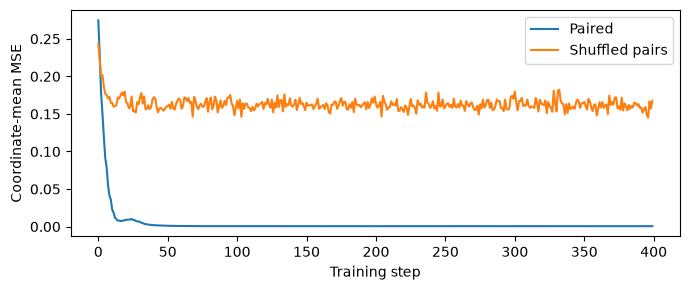

In [4]:
TRAIN_STEPS, BATCH_SIZE, LEARNING_RATE = 400, 128, 1e-2
batch_rng = torch.Generator().manual_seed(SEED + 3)
batches = torch.randint(len(train_v), (TRAIN_STEPS, BATCH_SIZE), generator=batch_rng).to(device)
shuffle = torch.randperm(len(train_l), generator=torch.Generator().manual_seed(SEED + 4)).to(device)
models = {"Paired": paired_model, "Shuffled pairs": shuffled_model}
targets = {"Paired": train_l, "Shuffled pairs": train_l[shuffle]}
histories = {}
for name, model in models.items():
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    for indices in batches:
        loss = F.mse_loss(model(train_v[indices]), targets[name][indices])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    histories[name] = history
    print(name, "final training loss:", history[-1])
plt.figure(figsize=(7, 3))
for name, history in histories.items():
    plt.plot(history, label=name)
plt.xlabel("Training step")
plt.ylabel("Coordinate-mean MSE")
plt.legend()
plt.tight_layout()
plt.show()


## 5. 独立测试集上的检索与相似度矩阵

每个矩阵的行是投影后的特征，列是目标语言特征。对角线对应正确配对；只展示前 16 对，Recall@1 仍在全部 128 对上计算。三个图使用相同范围并各自提供 colorbar。


Untrained        MSE=0.26352 | paired cosine=-0.0330 | Recall@1=0.0000
Paired           MSE=0.00061 | paired cosine=0.9977 | Recall@1=1.0000
Shuffled pairs   MSE=0.16163 | paired cosine=0.1628 | Recall@1=0.0078


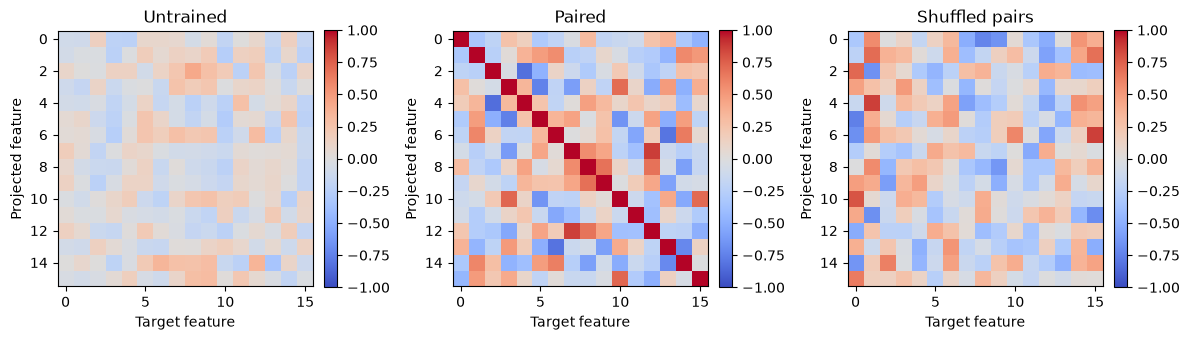

In [5]:
results = {"Untrained": before}
results.update({name: evaluate_projector(model) for name, model in models.items()})
for name, result in results.items():
    print(f"{name:16s} MSE={result['mse']:.5f} | paired cosine={result['paired_cosine']:.4f}"
          f" | Recall@1={result['recall_at_1']:.4f}")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
with torch.no_grad():
    for ax, (name, model) in zip(axes, [("Untrained", initial), *models.items()]):
        sim = F.normalize(model(test_v[:16]), dim=-1) @ F.normalize(test_l[:16], dim=-1).T
        im = ax.imshow(sim.cpu(), cmap="coolwarm", vmin=-1, vmax=1)
        ax.set(title=name, xlabel="Target feature", ylabel="Projected feature")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()
assert all(math.isfinite(value) for row in results.values() for value in row.values())


## 6. 解释范围

线性层不只会“改变维度”；合适的配对监督能使其学习这里预先构造的映射。是否学成功应读取上面的测试指标，而不能只比较两个独立随机向量的一次 cosine similarity。

该实验验证共同因素已存在时的映射学习，没有实现真实图文语义训练、对比预训练或跨分布泛化。可以改变噪声强度，或让目标包含非线性项，再比较 Linear 与 MLP，但应保持数据和评价协议一致。

[项目首页](../README.md) · [上一节](01_Multimodal_Tokenization.ipynb) · [下一节：融合机制](03_Cross_Attention_and_Fusion.ipynb)

参考：[LLaVA](https://llava-vl.github.io/) 展示可训练投影连接视觉编码器和语言模型；本实验只隔离映射学习机制。
